# 02 — Avaliação multieventos de cheia nas 8 bacias

Este notebook usa as séries diárias observadas e simuladas dos três cenários para avaliar vários eventos em uma única execução. Para quatro eventos, oito bacias e três configurações, podem existir até 96 avaliações. Quando uma bacia ou configuração não possuir dados suficientes em determinado evento, essa combinação será ignorada e registrada em uma tabela de problemas, sem interromper as demais análises.

Para cada bacia, configuração e evento, são calculados:

- **erro da magnitude do pico (%)**: positivo = superestimação;
- **deslocamento do pico (dias)**: positivo = pico simulado atrasado;
- **erro do volume total do hidrograma (%)**: positivo = superestimação;
- NSE e RMSE dentro da janela do evento.


In [10]:
from pathlib import Path
import math
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)

# ============================================================
# USE OS MESMOS CAMINHOS DO NOTEBOOK DE MÉTRICAS GERAIS
# ============================================================
PASTA_DADOS = Path("dados_resultados")
PASTA_SAIDA = Path("saidas_eventos")

CONFIGURACOES = {
    "INDIVIDUAL": {
        "tipo": "pasta",
        "caminho": PASTA_DADOS / "individual",
    },
    "MULTI_8": {
        "tipo": "arquivo",
        "caminho": PASTA_DADOS / "multibacia_8.csv",
    },
    "MULTI_39": {
        "tipo": "arquivo",
        "caminho": PASTA_DADOS / "multibacia_39.csv",
    },
}

# Se vazio, detecta as bacias automaticamente.
BACIAS_AVALIACAO = []

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)


In [11]:
def normalizar_nome_coluna(nome):
    """Remove acentos e padroniza o nome para facilitar o reconhecimento."""
    texto = unicodedata.normalize("NFKD", str(nome))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = re.sub(r"[^a-zA-Z0-9]+", "_", texto.lower()).strip("_")
    return texto


ALIASES = {
    "bacia": [
        "bacia", "basin", "basin_id", "gauge_id", "gauge", "station_id",
        "codigo_bacia", "codigo_estacao"
    ],
    "data": ["data", "date", "datetime", "time", "tempo"],
    "qobs_m3s": [
        "qobs_m3s", "streamflow_m3s_obs", "qobs", "q_obs", "obs",
        "observado", "observada", "vazao_observada", "vazao_obs"
    ],
    "qsim_m3s": [
        "qsim_m3s", "streamflow_m3s_sim", "qsim", "q_sim", "sim",
        "simulado", "simulada", "vazao_simulada", "vazao_sim"
    ],
    "NSE": ["nse", "nse_bacia", "nash_sutcliffe", "nash_sutcliffe_efficiency"],
}


def ler_csv_robusto(caminho):
    """Lê CSV separado por vírgula, ponto e vírgula, tabulação ou espaços."""
    caminho = Path(caminho)
    tentativas = [
        {"sep": None, "engine": "python", "decimal": ","},
        {"sep": ";", "engine": "python", "decimal": ","},
        {"sep": "\t", "engine": "python", "decimal": ","},
        {"sep": r"\s+", "engine": "python", "decimal": "."},
        {"sep": ",", "engine": "python", "decimal": "."},
    ]

    melhor = None
    melhor_chave = (-1, -1)
    erros = []
    nomes_reconhecidos = {
        alias
        for aliases in ALIASES.values()
        for alias in aliases
    }
    for argumentos in tentativas:
        try:
            candidato = pd.read_csv(
                caminho,
                dtype=str,
                encoding="utf-8-sig",
                **argumentos,
            )
            colunas_normalizadas = {
                normalizar_nome_coluna(c) for c in candidato.columns
            }
            pontuacao = len(colunas_normalizadas.intersection(nomes_reconhecidos))
            chave = (pontuacao, candidato.shape[1])
            if melhor is None or chave > melhor_chave:
                melhor = candidato
                melhor_chave = chave
        except Exception as erro:
            erros.append(str(erro))

    if melhor is None:
        raise ValueError(f"Não foi possível ler {caminho}. Erros: {erros[:2]}")

    melhor.columns = [str(c).strip() for c in melhor.columns]
    return melhor


def para_numero(serie):
    texto = serie.astype(str).str.strip()
    texto = texto.replace({"": np.nan, "nan": np.nan, "None": np.nan, "-": np.nan})
    texto = texto.str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")


def para_data(serie):
    """Reconhece datas ISO (ano-mês-dia) e datas brasileiras (dia/mês/ano)."""
    texto = serie.astype(str).str.strip()
    amostra = texto[~texto.isin(["", "nan", "None"])]
    proporcao_iso = amostra.str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}").mean()
    if pd.notna(proporcao_iso) and proporcao_iso >= 0.8:
        return pd.to_datetime(texto, errors="coerce", yearfirst=True)
    return pd.to_datetime(texto, errors="coerce", dayfirst=True)


def padronizar_colunas(df, caminho):
    """Converte nomes usuais do NeuralHydrology para os nomes usados aqui."""
    df = df.copy()
    normalizadas = {normalizar_nome_coluna(c): c for c in df.columns}
    renomear = {}

    for destino, aliases in ALIASES.items():
        for alias in aliases:
            if alias in normalizadas:
                renomear[normalizadas[alias]] = destino
                break

    df = df.rename(columns=renomear)

    if "bacia" not in df.columns:
        encontrados = re.findall(r"(?<!\d)(\d{7,8})(?!\d)", Path(caminho).stem)
        if encontrados:
            df["bacia"] = encontrados[-1]
        else:
            raise ValueError(
                f"{Path(caminho).name}: não encontrei a coluna da bacia e "
                "o nome do arquivo não contém um código de 7 ou 8 dígitos."
            )

    df["bacia"] = (
        df["bacia"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
    )

    for coluna in ["qobs_m3s", "qsim_m3s", "NSE"]:
        if coluna in df.columns:
            df[coluna] = para_numero(df[coluna])

    if "data" in df.columns:
        df["data"] = para_data(df["data"])

    return df


def listar_arquivos(especificacao):
    caminho = Path(especificacao["caminho"])
    tipo = especificacao["tipo"].lower()

    if tipo == "pasta":
        if not caminho.exists():
            raise FileNotFoundError(f"Pasta não encontrada: {caminho.resolve()}")
        arquivos = sorted(caminho.glob("*.csv"))
        if not arquivos:
            raise FileNotFoundError(f"Nenhum CSV encontrado em: {caminho.resolve()}")
        return arquivos

    if tipo == "arquivo":
        if not caminho.exists():
            raise FileNotFoundError(f"Arquivo não encontrado: {caminho.resolve()}")
        return [caminho]

    raise ValueError("O campo 'tipo' deve ser 'pasta' ou 'arquivo'.")


def carregar_configuracao(nome, especificacao):
    partes = []
    for caminho in listar_arquivos(especificacao):
        df = padronizar_colunas(ler_csv_robusto(caminho), caminho)
        df["arquivo_origem"] = caminho.name
        partes.append(df)

    resultado = pd.concat(partes, ignore_index=True, sort=False)
    resultado["configuracao"] = nome
    return resultado


In [12]:
# Carrega e valida as séries das três configurações
partes_series = []

for nome, especificacao in CONFIGURACOES.items():
    dados = carregar_configuracao(nome, especificacao)
    obrigatorias = {"bacia", "data", "qobs_m3s", "qsim_m3s"}
    ausentes = obrigatorias.difference(dados.columns)
    if ausentes:
        raise ValueError(
            f"A configuração {nome} não possui as colunas: {sorted(ausentes)}. "
            "Este notebook precisa das séries, não apenas do NSE."
        )

    dados = dados.dropna(subset=["data"]).copy()
    duplicadas = dados.duplicated(["bacia", "data"], keep=False)
    if duplicadas.any():
        exemplo = dados.loc[duplicadas, ["bacia", "data", "arquivo_origem"]].head()
        display(exemplo)
        raise ValueError(f"Existem datas duplicadas na configuração {nome}.")

    partes_series.append(
        dados[[
            "configuracao", "bacia", "data", "qobs_m3s", "qsim_m3s", "arquivo_origem"
        ]]
    )

series = pd.concat(partes_series, ignore_index=True)

disponiveis = {
    nome: set(series.loc[series["configuracao"] == nome, "bacia"])
    for nome in CONFIGURACOES
}

if BACIAS_AVALIACAO:
    bacias = [str(b).strip() for b in BACIAS_AVALIACAO]
else:
    bacias = sorted(set().union(*disponiveis.values()))

faltantes = [
    {"configuracao": nome, "bacia_ausente": bacia}
    for nome, conjunto in disponiveis.items()
    for bacia in bacias
    if bacia not in conjunto
]

if faltantes:
    print("Bacias ausentes em alguma configuração (serão ignoradas quando necessário):")
    display(pd.DataFrame(faltantes))
    warnings.warn(
        "Nem todas as configurações possuem as mesmas bacias. "
        "O notebook continuará e exportará somente as combinações disponíveis."
    )

if len(bacias) != 8:
    warnings.warn(f"Foram detectadas {len(bacias)} bacias, e não 8: {bacias}")

series = series[series["bacia"].isin(bacias)].copy()
series = series.sort_values(["configuracao", "bacia", "data"]).reset_index(drop=True)

# Confere se a vazão observada é a mesma entre os três cenários.
obs_largo = series.pivot_table(
    index=["bacia", "data"], columns="configuracao", values="qobs_m3s", aggfunc="first"
)
amplitude_obs = obs_largo.max(axis=1) - obs_largo.min(axis=1)
divergencias_obs = int((amplitude_obs > 1e-6).sum())

print(f"Bacias carregadas ({len(bacias)}): {', '.join(bacias)}")
print(f"Registros de séries: {len(series):,}")
print(f"Datas com qobs divergente entre cenários: {divergencias_obs}")

if divergencias_obs:
    warnings.warn(
        "A série observada não é idêntica em todas as configurações. "
        "Confira se foi usado o mesmo período e o mesmo pós-processamento."
    )


Bacias carregadas (8): 86100000, 86160000, 86410000, 86480000, 86500000, 86510000, 86560000, 86580000
Registros de séries: 46,032
Datas com qobs divergente entre cenários: 9165


C:\Users\Usuario\AppData\Local\Temp\ipykernel_13292\1420390965.py:72: UserWarning: A série observada não é idêntica em todas as configurações. Confira se foi usado o mesmo período e o mesmo pós-processamento.
  warnings.warn(


## Defina os eventos

Edite a célula seguinte para adicionar ou remover eventos. Use `bacia="TODAS"` quando o mesmo intervalo será aplicado às 8 bacias. Se cada bacia tiver uma janela própria, coloque uma linha para cada bacia.

Configuração atual:

```python
EVENTOS = pd.DataFrame([
    {"evento": "Cheia_1", "bacia": "TODAS", "inicio": "2020-07-05", "fim": "2020-07-17"},
    {"evento": "Cheia_2", "bacia": "TODAS", "inicio": "2022-06-04", "fim": "2022-06-13"},
    {"evento": "Cheia_3", "bacia": "TODAS", "inicio": "2023-09-01", "fim": "2023-09-12"},
    {"evento": "Cheia_4", "bacia": "TODAS", "inicio": "2023-10-02", "fim": "2023-10-12"},
])
```


In [13]:
# ============================================================
# PREENCHA AQUI AS DATAS DOS EVENTOS ESCOLHIDOS
# ============================================================
EVENTOS = pd.DataFrame([
    {"evento": "Cheia_1", "bacia": "TODAS", "inicio": "2020-07-05", "fim": "2020-07-17"},
    {"evento": "Cheia_2", "bacia": "TODAS", "inicio": "2022-06-04", "fim": "2022-06-13"},
    {"evento": "Cheia_3", "bacia": "TODAS", "inicio": "2023-09-01", "fim": "2023-09-12"},
    {"evento": "Cheia_4", "bacia": "TODAS", "inicio": "2023-10-02", "fim": "2023-10-12"},
])

if EVENTOS.empty:
    raise ValueError(
        "Preencha a tabela EVENTOS com pelo menos uma janela e rode novamente esta célula."
    )


In [14]:
def expandir_eventos(eventos, bacias_validas):
    obrigatorias = {"evento", "bacia", "inicio", "fim"}
    ausentes = obrigatorias.difference(eventos.columns)
    if ausentes:
        raise ValueError(f"Faltam colunas na tabela EVENTOS: {sorted(ausentes)}")

    registros = []
    for _, linha in eventos.iterrows():
        alvo = str(linha["bacia"]).strip()
        if alvo.upper() in {"TODAS", "TODOS", "ALL", "*"}:
            alvos = bacias_validas
        else:
            alvos = [alvo]

        for bacia in alvos:
            if bacia not in bacias_validas:
                raise ValueError(f"A bacia {bacia} do evento não está nos dados.")
            registros.append({
                "evento": str(linha["evento"]).strip(),
                "bacia": bacia,
                "inicio": pd.Timestamp(linha["inicio"]),
                "fim": pd.Timestamp(linha["fim"]),
            })

    expandidos = pd.DataFrame(registros)
    if (expandidos["fim"] < expandidos["inicio"]).any():
        raise ValueError("Existe evento com data final anterior à data inicial.")
    if expandidos.duplicated(["evento", "bacia"]).any():
        raise ValueError("Existe evento duplicado para a mesma bacia.")
    return expandidos


def nse_evento(qobs, qsim):
    denominador = np.sum((qobs - np.mean(qobs)) ** 2)
    if denominador == 0:
        return np.nan
    return 1 - np.sum((qsim - qobs) ** 2) / denominador


def erro_percentual(simulado, observado):
    if observado == 0:
        return np.nan
    return 100 * (simulado - observado) / observado


def avaliar_janela(grupo, evento, bacia, inicio, fim, configuracao):
    janela = grupo.loc[
        (grupo["data"] >= inicio) & (grupo["data"] <= fim),
        ["data", "qobs_m3s", "qsim_m3s"],
    ].sort_values("data").reset_index(drop=True)

    if janela.empty:
        raise ValueError("não existem dados dentro da janela")
    if len(janela) < 2:
        raise ValueError("a janela possui menos de duas datas")
    if janela[["qobs_m3s", "qsim_m3s"]].isna().any().any():
        quantidade = int(janela[["qobs_m3s", "qsim_m3s"]].isna().any(axis=1).sum())
        raise ValueError(f"existem {quantidade} datas com qobs ou qsim ausente")

    diferencas = janela["data"].diff().dt.total_seconds().dropna()
    passo_segundos = float(diferencas.median())
    if passo_segundos <= 0:
        raise ValueError("passo temporal inválido")
    if not np.allclose(diferencas, passo_segundos, rtol=0, atol=1):
        raise ValueError("a série possui lacunas ou passo temporal irregular na janela")

    idx_obs = janela["qobs_m3s"].idxmax()
    idx_sim = janela["qsim_m3s"].idxmax()

    pico_obs = float(janela.loc[idx_obs, "qobs_m3s"])
    pico_sim = float(janela.loc[idx_sim, "qsim_m3s"])
    data_pico_obs = janela.loc[idx_obs, "data"]
    data_pico_sim = janela.loc[idx_sim, "data"]

    deslocamento_dias = (data_pico_sim - data_pico_obs).total_seconds() / 86400

    # Cada valor é a vazão média do passo (por exemplo, média diária).
    volume_obs_hm3 = janela["qobs_m3s"].sum() * passo_segundos / 1_000_000
    volume_sim_hm3 = janela["qsim_m3s"].sum() * passo_segundos / 1_000_000

    qobs = janela["qobs_m3s"].to_numpy(dtype=float)
    qsim = janela["qsim_m3s"].to_numpy(dtype=float)
    erro_pico_pct = erro_percentual(pico_sim, pico_obs)
    erro_volume_pct = erro_percentual(volume_sim_hm3, volume_obs_hm3)

    return {
        "evento": evento,
        "bacia": bacia,
        "configuracao": configuracao,
        "inicio": inicio,
        "fim": fim,
        "n_passos": len(janela),
        "passo_horas": passo_segundos / 3600,
        "pico_obs_m3s": pico_obs,
        "pico_sim_m3s": pico_sim,
        "data_pico_obs": data_pico_obs,
        "data_pico_sim": data_pico_sim,
        "erro_pico_m3s": pico_sim - pico_obs,
        "erro_pico_pct": erro_pico_pct,
        "erro_abs_pico_pct": abs(erro_pico_pct),
        "deslocamento_pico_dias": deslocamento_dias,
        "deslocamento_abs_dias": abs(deslocamento_dias),
        "volume_obs_hm3": volume_obs_hm3,
        "volume_sim_hm3": volume_sim_hm3,
        "erro_volume_hm3": volume_sim_hm3 - volume_obs_hm3,
        "erro_volume_pct": erro_volume_pct,
        "erro_abs_volume_pct": abs(erro_volume_pct),
        "NSE_evento": nse_evento(qobs, qsim),
        "RMSE_evento_m3s": float(np.sqrt(np.mean((qsim - qobs) ** 2))),
    }


eventos_expandidos = expandir_eventos(EVENTOS, bacias)
print(f"Eventos definidos: {EVENTOS['evento'].nunique()}")
print(f"Linhas após expansão para as bacias: {len(eventos_expandidos)}")
display(eventos_expandidos)


Eventos definidos: 4
Linhas após expansão para as bacias: 32


,evento,bacia,inicio,fim
0,Cheia_1,86100000,2020-07-05,2020-07-17
1,Cheia_1,86160000,2020-07-05,2020-07-17
2,Cheia_1,86410000,2020-07-05,2020-07-17
3,Cheia_1,86480000,2020-07-05,2020-07-17
4,Cheia_1,86500000,2020-07-05,2020-07-17
5,Cheia_1,86510000,2020-07-05,2020-07-17
6,Cheia_1,86560000,2020-07-05,2020-07-17
7,Cheia_1,86580000,2020-07-05,2020-07-17
8,Cheia_2,86100000,2022-06-04,2022-06-13
9,Cheia_2,86160000,2022-06-04,2022-06-13


In [15]:
# Calcula os indicadores de todos os eventos, bacias e configurações
resultados = []
erros = []

for _, evento_linha in eventos_expandidos.iterrows():
    for configuracao in CONFIGURACOES:
        grupo = series.loc[
            (series["configuracao"] == configuracao)
            & (series["bacia"] == evento_linha["bacia"])
        ]
        try:
            resultados.append(
                avaliar_janela(
                    grupo=grupo,
                    evento=evento_linha["evento"],
                    bacia=evento_linha["bacia"],
                    inicio=evento_linha["inicio"],
                    fim=evento_linha["fim"],
                    configuracao=configuracao,
                )
            )
        except Exception as erro:
            erros.append({
                "evento": evento_linha["evento"],
                "bacia": evento_linha["bacia"],
                "configuracao": configuracao,
                "erro": str(erro),
            })

colunas_erros = ["evento", "bacia", "configuracao", "erro"]
tabela_erros = pd.DataFrame(erros, columns=colunas_erros)

if not tabela_erros.empty:
    print("Combinações ignoradas por falta de dados completos:")
    display(tabela_erros)
    print(
        "A execução continuará e exportará todas as combinações válidas."
    )

if not resultados:
    raise ValueError(
        "Nenhuma combinação evento-bacia-configuração possui dados suficientes."
    )

tabela_eventos = pd.DataFrame(resultados).sort_values(
    ["evento", "bacia", "configuracao"]
).reset_index(drop=True)

numero_possivel = len(eventos_expandidos) * len(CONFIGURACOES)
print(f"Avaliações calculadas: {len(tabela_eventos)}")
print(f"Avaliações possíveis com dados completos: até {numero_possivel}")
print(f"Combinações ignoradas: {len(tabela_erros)}")

print("Resultados por evento:")
display(
    tabela_eventos.groupby("evento")
    .size()
    .reset_index(name="numero_resultados")
)

colunas_principais = [
    "evento", "bacia", "configuracao",
    "pico_obs_m3s", "pico_sim_m3s", "erro_pico_pct",
    "data_pico_obs", "data_pico_sim", "deslocamento_pico_dias",
    "volume_obs_hm3", "volume_sim_hm3", "erro_volume_pct",
    "NSE_evento", "RMSE_evento_m3s",
]

display(tabela_eventos[colunas_principais].round(3))


Combinações ignoradas por falta de dados completos:


,evento,bacia,configuracao,erro
0,Cheia_3,86480000,INDIVIDUAL,existem 10 datas com qobs ou qsim ausente
1,Cheia_3,86480000,MULTI_8,existem 10 datas com qobs ou qsim ausente
2,Cheia_3,86480000,MULTI_39,existem 10 datas com qobs ou qsim ausente
3,Cheia_3,86500000,INDIVIDUAL,existem 12 datas com qobs ou qsim ausente
4,Cheia_3,86500000,MULTI_8,existem 12 datas com qobs ou qsim ausente
5,Cheia_3,86500000,MULTI_39,existem 12 datas com qobs ou qsim ausente
6,Cheia_3,86560000,INDIVIDUAL,existem 12 datas com qobs ou qsim ausente
7,Cheia_3,86560000,MULTI_8,existem 12 datas com qobs ou qsim ausente
8,Cheia_3,86560000,MULTI_39,existem 12 datas com qobs ou qsim ausente
9,Cheia_3,86580000,INDIVIDUAL,existem 8 datas com qobs ou qsim ausente


A execução continuará e exportará todas as combinações válidas.
Avaliações calculadas: 72
Avaliações possíveis com dados completos: até 96
Combinações ignoradas: 24
Resultados por evento:


,evento,numero_resultados
0,Cheia_1,24
1,Cheia_2,24
2,Cheia_3,12
3,Cheia_4,12


C:\Users\Usuario\AppData\Local\Temp\ipykernel_13292\3140372052.py:69: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tabela_eventos[colunas_principais].round(3))


,evento,bacia,configuracao,pico_obs_m3s,pico_sim_m3s,erro_pico_pct,data_pico_obs,data_pico_sim,deslocamento_pico_dias,volume_obs_hm3,volume_sim_hm3,erro_volume_pct,NSE_evento,RMSE_evento_m3s
0,Cheia_1,86100000,INDIVIDUAL,1139.190,868.394,-23.771,2020-07-08,2020-07-08,0.0,455.139,361.867,-20.493,0.615,190.222
1,Cheia_1,86100000,MULTI_39,1139.190,1232.850,8.222,2020-07-08,2020-07-08,0.0,455.139,409.641,-9.996,0.703,167.257
2,Cheia_1,86100000,MULTI_8,1139.190,919.733,-19.264,2020-07-08,2020-07-08,0.0,455.139,379.323,-16.658,0.629,186.845
3,Cheia_1,86160000,INDIVIDUAL,505.173,665.022,31.642,2020-07-08,2020-07-08,0.0,213.169,234.010,9.777,0.733,62.473
4,Cheia_1,86160000,MULTI_39,505.173,1176.707,132.932,2020-07-08,2020-07-08,0.0,213.169,302.871,42.080,-1.858,204.382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Cheia_4,86410000,MULTI_39,1601.750,945.855,-40.949,2023-10-07,2023-10-12,5.0,688.556,415.632,-39.637,0.430,369.422
68,Cheia_4,86410000,MULTI_8,1601.750,1102.736,-31.154,2023-10-07,2023-10-12,5.0,688.556,400.703,-41.805,0.362,390.764
69,Cheia_4,86510000,INDIVIDUAL,5275.650,4459.600,-15.468,2023-10-08,2023-10-08,0.0,1821.281,2069.600,13.634,0.774,619.250
70,Cheia_4,86510000,MULTI_39,5275.650,4570.980,-13.357,2023-10-08,2023-10-12,4.0,1821.281,2143.319,17.682,0.547,876.207


In [16]:
# Resumo separado para cada evento e configuração
resumo_por_evento = (
    tabela_eventos.groupby(["evento", "configuracao"], observed=True)
    .agg(
        n_bacias=("bacia", "nunique"),
        n_avaliacoes=("evento", "count"),
        erro_pico_medio_pct=("erro_pico_pct", "mean"),
        erro_abs_pico_medio_pct=("erro_abs_pico_pct", "mean"),
        deslocamento_medio_dias=("deslocamento_pico_dias", "mean"),
        deslocamento_abs_medio_dias=("deslocamento_abs_dias", "mean"),
        erro_volume_medio_pct=("erro_volume_pct", "mean"),
        erro_abs_volume_medio_pct=("erro_abs_volume_pct", "mean"),
        NSE_evento_medio=("NSE_evento", "mean"),
        NSE_evento_mediano=("NSE_evento", "median"),
        RMSE_evento_medio_m3s=("RMSE_evento_m3s", "mean"),
    )
    .reset_index()
)

# Resumo geral das configurações considerando todos os eventos
resumo_geral = (
    tabela_eventos.groupby("configuracao", observed=True)
    .agg(
        n_eventos=("evento", "nunique"),
        n_bacias=("bacia", "nunique"),
        n_avaliacoes=("evento", "count"),
        erro_pico_medio_pct=("erro_pico_pct", "mean"),
        erro_abs_pico_medio_pct=("erro_abs_pico_pct", "mean"),
        deslocamento_medio_dias=("deslocamento_pico_dias", "mean"),
        deslocamento_abs_medio_dias=("deslocamento_abs_dias", "mean"),
        erro_volume_medio_pct=("erro_volume_pct", "mean"),
        erro_abs_volume_medio_pct=("erro_abs_volume_pct", "mean"),
        NSE_evento_medio=("NSE_evento", "mean"),
        NSE_evento_mediano=("NSE_evento", "median"),
        RMSE_evento_medio_m3s=("RMSE_evento_m3s", "mean"),
    )
    .reindex(list(CONFIGURACOES))
    .reset_index()
)

print("Resumo por evento e configuração:")
display(resumo_por_evento.round(3))

print("Resumo geral das configurações:")
display(resumo_geral.round(3))

# Tabela compacta: útil para conferir, por evento e bacia, qual cenário teve menor erro.
comparacao_erros = tabela_eventos.pivot_table(
    index=["evento", "bacia"],
    columns="configuracao",
    values=[
        "erro_abs_pico_pct", "deslocamento_abs_dias",
        "erro_abs_volume_pct", "NSE_evento"
    ],
)
display(comparacao_erros.round(3))


Resumo por evento e configuração:


,evento,configuracao,n_bacias,n_avaliacoes,erro_pico_medio_pct,erro_abs_pico_medio_pct,deslocamento_medio_dias,deslocamento_abs_medio_dias,erro_volume_medio_pct,erro_abs_volume_medio_pct,NSE_evento_medio,NSE_evento_mediano,RMSE_evento_medio_m3s
0,Cheia_1,INDIVIDUAL,8,8,-20.487,28.398,0.00,0.00,-12.980,15.424,0.711,0.754,362.333
1,Cheia_1,MULTI_39,8,8,16.888,35.944,0.00,0.00,4.922,16.115,0.425,0.757,342.990
2,Cheia_1,MULTI_8,8,8,-1.313,25.180,0.00,0.00,-4.280,15.450,0.660,0.878,289.263
3,Cheia_2,INDIVIDUAL,8,8,4.359,23.278,0.00,0.25,-3.156,12.080,0.645,0.668,78.484
4,Cheia_2,MULTI_39,8,8,10.726,27.730,0.00,0.25,3.971,13.388,0.497,0.577,121.716
5,Cheia_2,MULTI_8,8,8,4.435,21.916,0.00,0.25,-3.768,8.917,0.678,0.790,77.998
6,Cheia_3,INDIVIDUAL,4,4,-26.078,26.078,0.50,0.50,11.485,28.651,0.615,0.558,883.080
7,Cheia_3,MULTI_39,4,4,-8.825,29.017,0.00,0.50,18.506,44.534,0.470,0.688,809.985
8,Cheia_3,MULTI_8,4,4,-9.175,26.855,0.25,0.25,20.258,42.028,0.565,0.647,838.260
9,Cheia_4,INDIVIDUAL,4,4,-15.252,26.174,1.25,1.25,4.748,23.920,0.609,0.603,304.162


Resumo geral das configurações:


,configuracao,n_eventos,n_bacias,n_avaliacoes,erro_pico_medio_pct,erro_abs_pico_medio_pct,deslocamento_medio_dias,deslocamento_abs_medio_dias,erro_volume_medio_pct,erro_abs_volume_medio_pct,NSE_evento_medio,NSE_evento_mediano,RMSE_evento_medio_m3s
0,INDIVIDUAL,4,8,24,-12.264,25.934,0.292,0.375,-2.673,17.930,0.656,0.668,344.812
1,MULTI_8,4,8,24,-1.884,23.471,0.417,0.500,2.175,20.092,0.629,0.655,320.651
2,MULTI_39,4,8,24,5.797,30.554,0.375,0.542,7.456,21.967,0.473,0.668,351.671


NSE_evento                  deslocamento_abs_dias           \
configuracao     INDIVIDUAL MULTI_39 MULTI_8            INDIVIDUAL MULTI_39   
evento  bacia                                                                 
Cheia_1 86100000      0.615    0.703   0.629                   0.0      0.0   
        86160000      0.733   -1.858  -0.216                   0.0      0.0   
        86410000      0.887    0.953   0.952                   0.0      0.0   
        86480000      0.942    0.899   0.878                   0.0      0.0   
        86500000      0.242    0.340   0.370                   0.0      0.0   
        86510000      0.807    0.811   0.879                   0.0      0.0   
        86560000      0.776    0.702   0.903                   0.0      0.0   
        86580000      0.686    0.851   0.883                   0.0      0.0   
Cheia_2 86100000      0.650    0.509   0.483                   0.0      0.0   
        86160000      0.971    0.949   0.961                   0.0      0.0   
        86410000      0.685    0.364   0.885                   0.0      0.0   
        86480000      0.547    0.345   0.694                   0.0      0.0   
        86500000     -0.030   -0.521  -0.036                   1.0      1.0   
        86510000      0.951    0.752   0.952                   0.0      0.0   
        86560000      0.426    0.645   0.543                   1.0      1.0   
        86580000      0.955    0.934   0.939                   0.0      0.0   
Cheia_3 86100000      0.437    0.677   0.654                   1.0      1.0   
        86160000      0.906    0.786   0.668                   1.0      0.0   
        86410000      0.549   -0.283   0.297                   0.0      1.0   
        86510000      0.568    0.699   0.639                   0.0      0.0   
Cheia_4 86100000      0.577    0.659   0.527                   0.0      0.0   
        86160000      0.629    0.456   0.585                   0.0      0.0   
        86410000      0.457    0.430   0.362                   5.0      5.0   
        86510000      0.774    0.547   0.656                   0.0      4.0   

                         erro_abs_pico_pct                   \
configuracao     MULTI_8        INDIVIDUAL MULTI_39 MULTI_8   
evento  bacia                                                 
Cheia_1 86100000     0.0            23.771    8.222  19.264   
        86160000     0.0            31.642  132.932  77.871   
        86410000     0.0            22.254   14.518   7.917   
        86480000     0.0            12.821   20.001  27.567   
        86500000     0.0            33.117   11.824  19.061   
        86510000     0.0            27.803   31.758  12.551   
        86560000     0.0            26.812   35.655   9.682   
        86580000     0.0            48.962   32.644  27.527   
Cheia_2 86100000     0.0            44.014   51.948  54.231   
        86160000     0.0            11.820   16.070  15.502   
        86410000     0.0            38.507   52.676  22.828   
        86480000     0.0            23.639   44.693  31.368   
        86500000     1.0            46.348   51.959  38.677   
        86510000     0.0             0.173    0.264   6.499   
        86560000     1.0            19.843    3.057   6.032   
        86580000     0.0             1.880    1.175   0.188   
Cheia_3 86100000     1.0            30.148   34.599  26.125   
        86160000     0.0             1.890   25.088  27.445   
        86410000     0.0            19.823   15.295   7.914   
        86510000     0.0            52.450   41.084  45.934   
Cheia_4 86100000     0.0            31.490   22.854   9.599   
        86160000     0.0            21.845   30.683  22.819   
        86410000     5.0            35.893   40.949  31.154   
        86510000     4.0            15.468   13.357  15.554   

                 erro_abs_volume_pct                   
configuracao              INDIVIDUAL MULTI_39 MULTI_8  
evento  bacia                                          
Cheia_1 86100

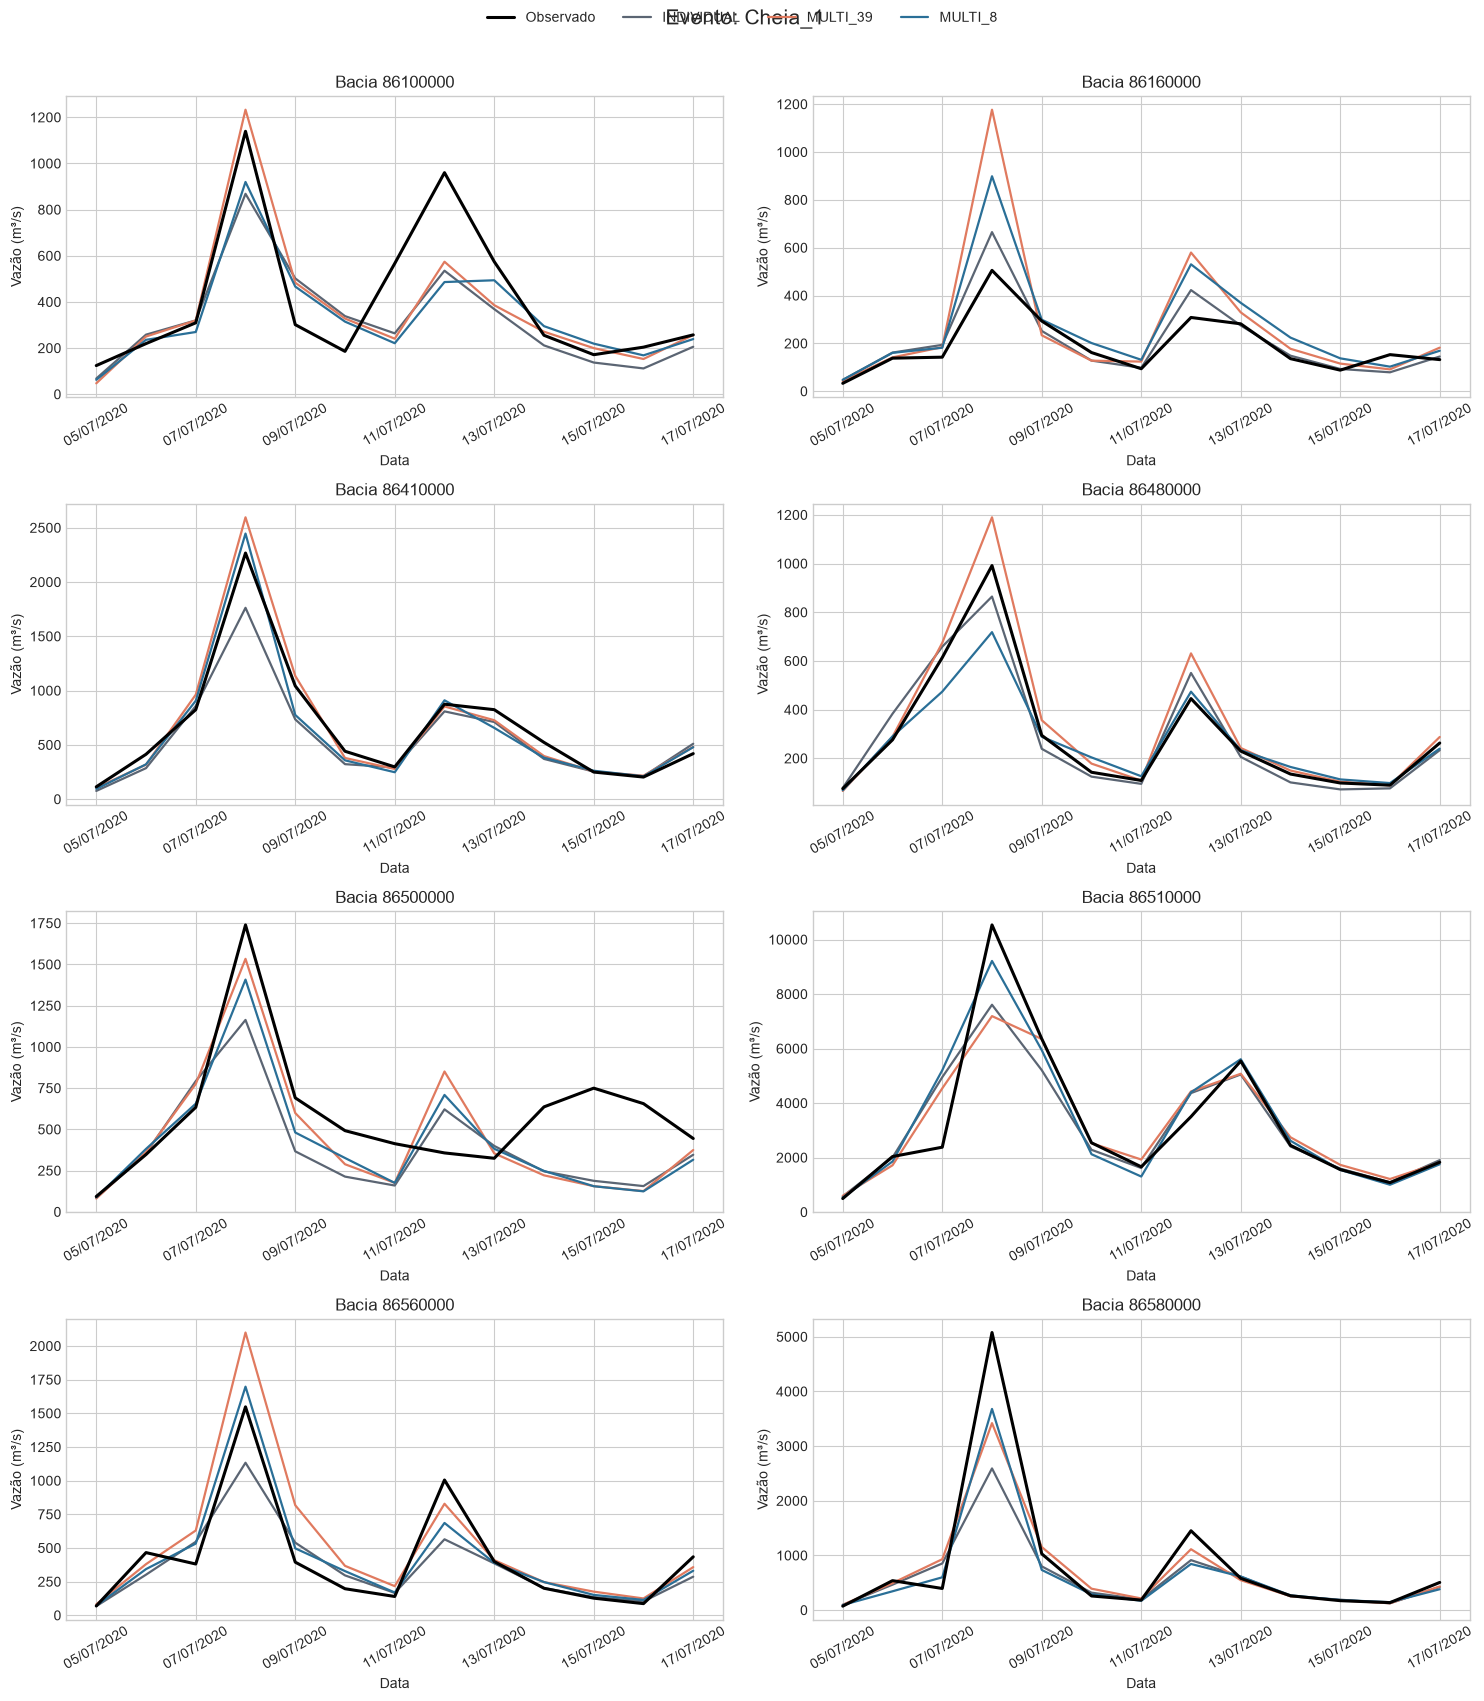

Figura salva em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_eventos\hidrogramas_Cheia_1.png


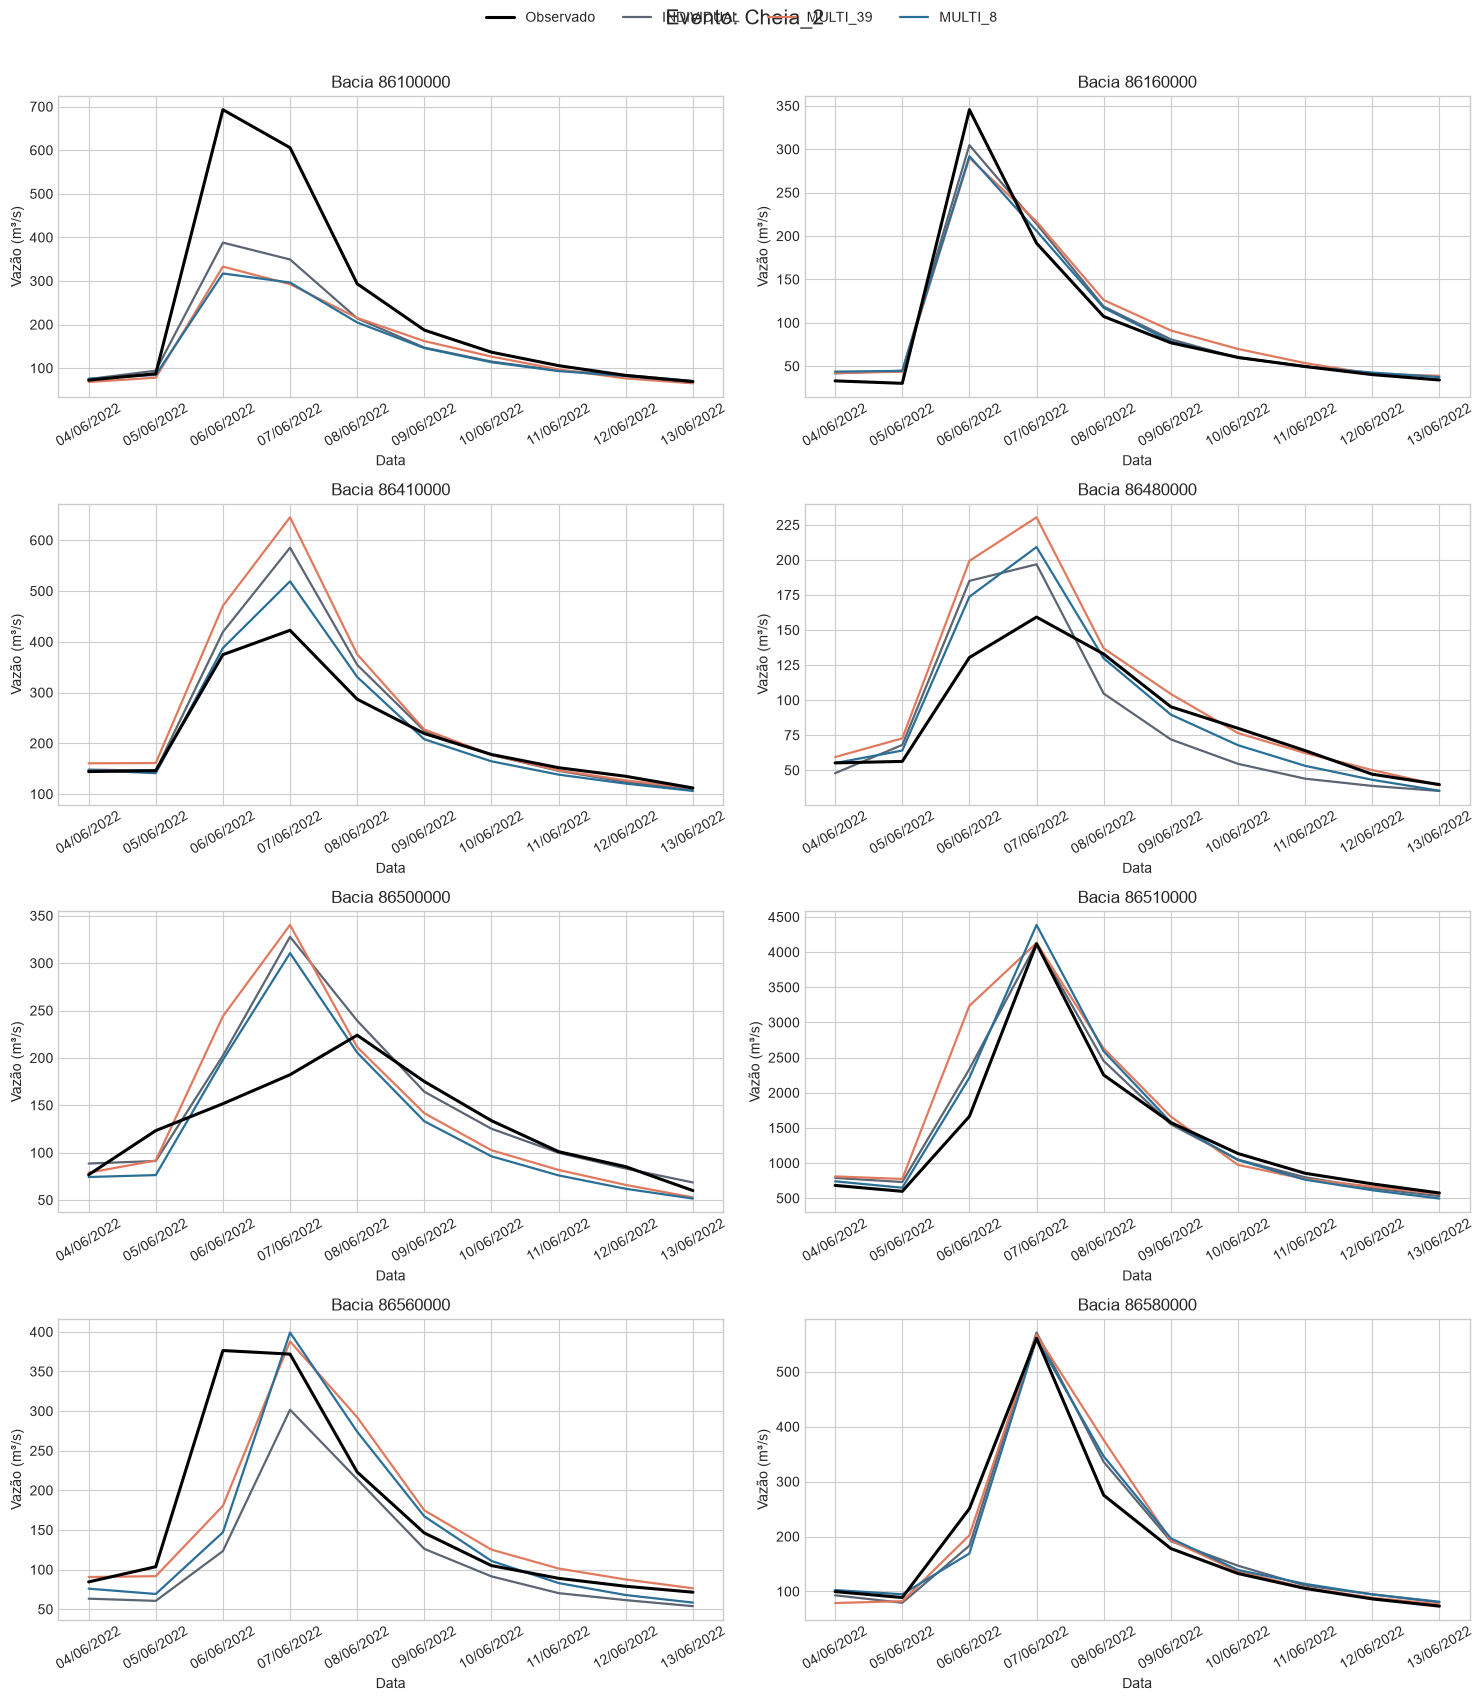

Figura salva em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_eventos\hidrogramas_Cheia_2.png


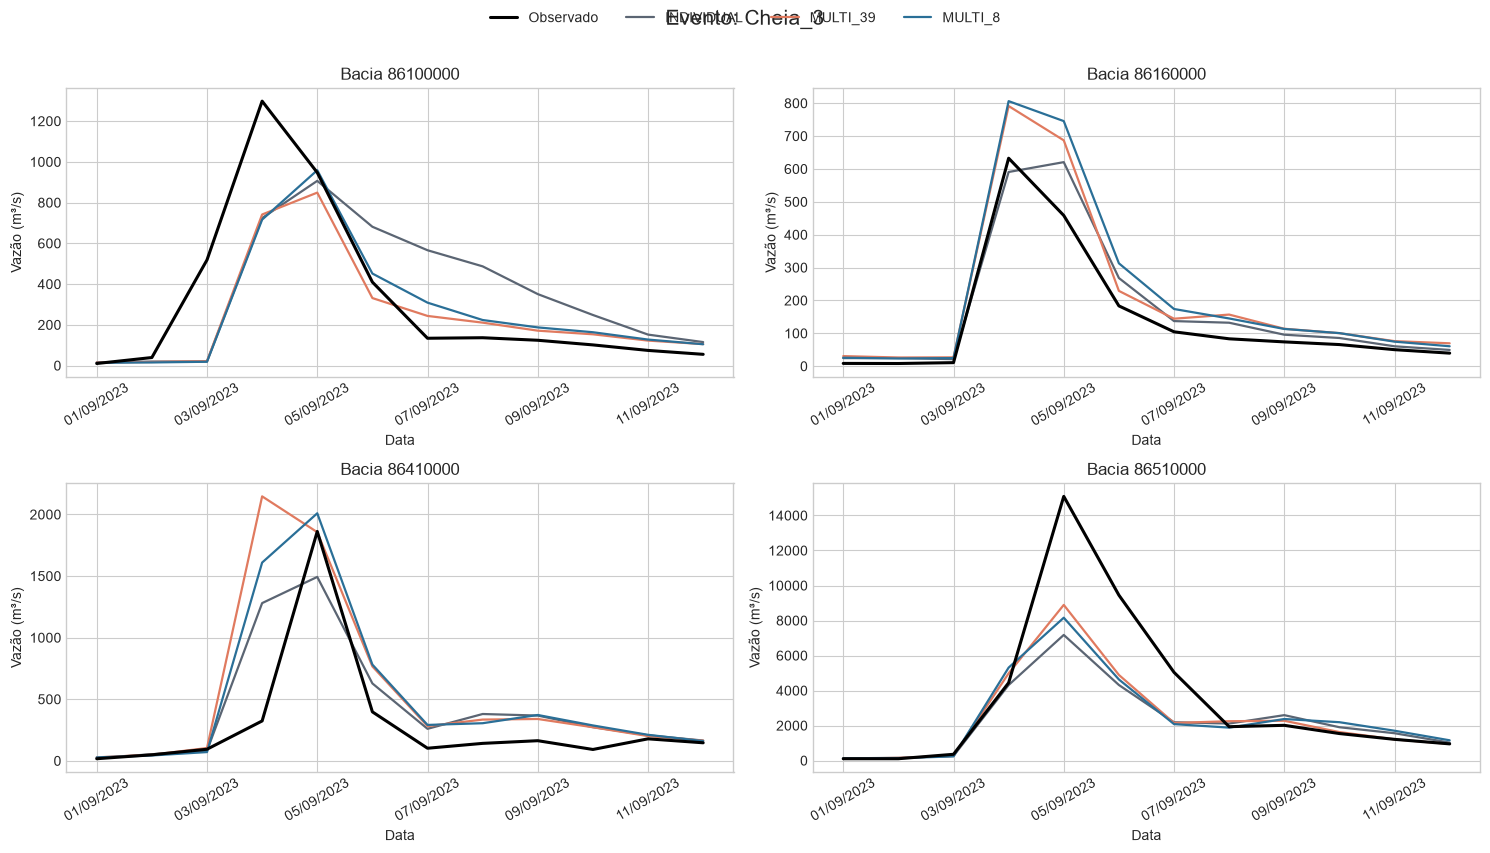

Figura salva em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_eventos\hidrogramas_Cheia_3.png


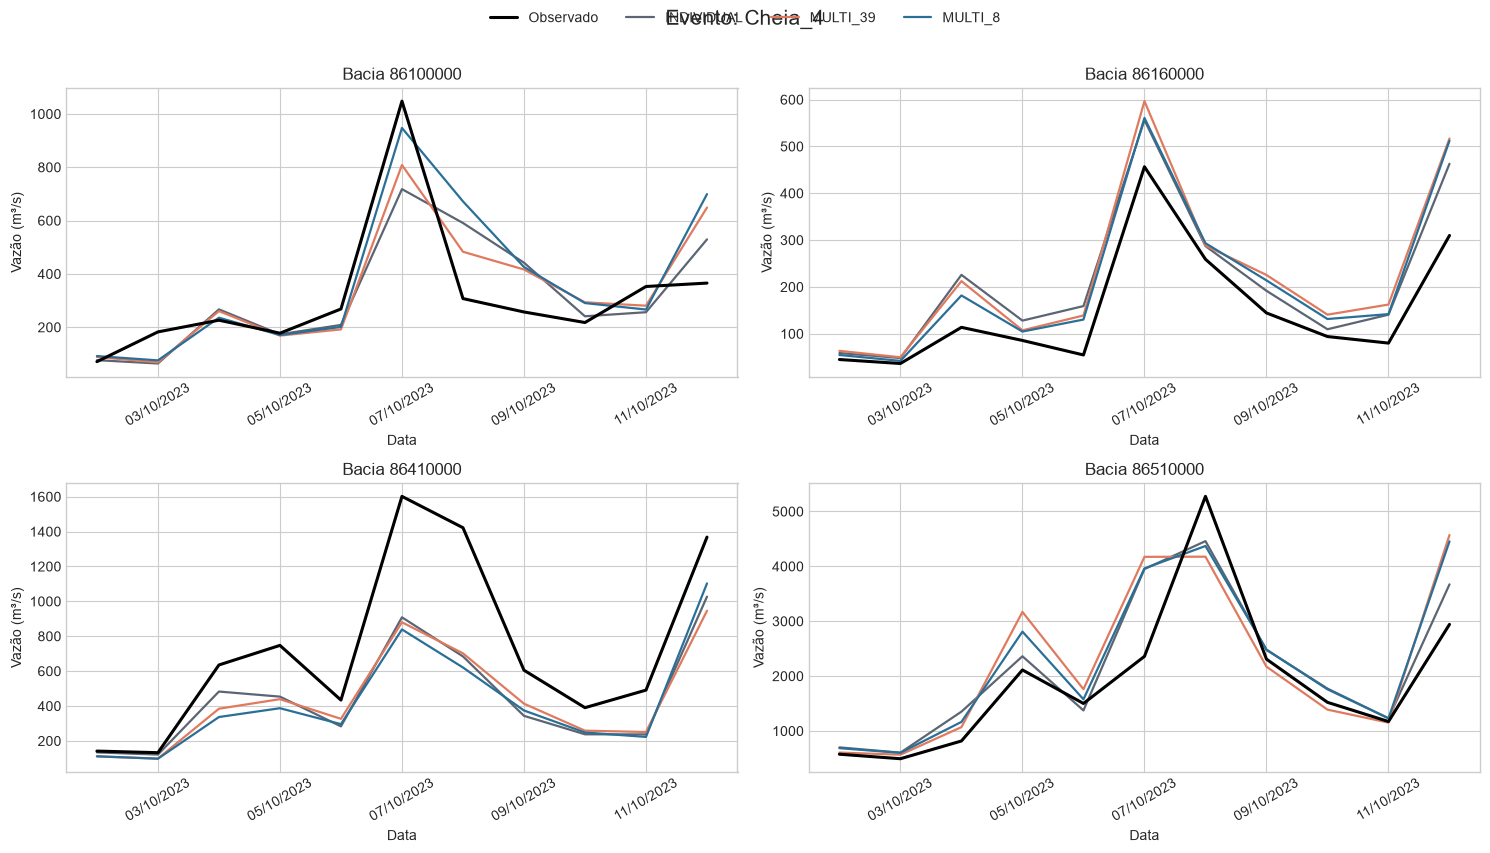

Figura salva em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_eventos\hidrogramas_Cheia_4.png


In [17]:
# Hidrogramas: uma figura por evento, somente com as bacias que têm resultados
cores_sim = {
    "INDIVIDUAL": "#5B6573",
    "MULTI_8": "#2A6F97",
    "MULTI_39": "#E07A5F",
}

# Mantém apenas as combinações evento-bacia que produziram pelo menos um resultado.
eventos_validos = (
    tabela_eventos[["evento", "bacia", "inicio", "fim"]]
    .drop_duplicates()
    .sort_values(["evento", "bacia"])
    .reset_index(drop=True)
)

for nome_evento, definicoes in eventos_validos.groupby("evento", sort=False):
    definicoes = definicoes.reset_index(drop=True)
    n = len(definicoes)
    colunas = 2 if n > 1 else 1
    linhas = math.ceil(n / colunas)

    fig, eixos = plt.subplots(
        linhas, colunas,
        figsize=(15, 4.2 * linhas),
        squeeze=False,
        sharex=False,
    )
    eixos = eixos.flatten()

    for i, definicao in definicoes.iterrows():
        ax = eixos[i]
        bacia = definicao["bacia"]
        inicio = definicao["inicio"]
        fim = definicao["fim"]

        configuracoes_validas = (
            tabela_eventos.loc[
                (tabela_eventos["evento"] == nome_evento)
                & (tabela_eventos["bacia"] == bacia),
                "configuracao",
            ]
            .drop_duplicates()
            .tolist()
        )

        # Usa a primeira configuração válida apenas para desenhar o observado.
        configuracao_referencia = configuracoes_validas[0]
        referencia = series.loc[
            (series["configuracao"] == configuracao_referencia)
            & (series["bacia"] == bacia)
            & (series["data"] >= inicio)
            & (series["data"] <= fim)
        ].sort_values("data")

        ax.plot(
            referencia["data"], referencia["qobs_m3s"],
            color="black", linewidth=2.2, label="Observado", zorder=5
        )

        for configuracao in configuracoes_validas:
            trecho = series.loc[
                (series["configuracao"] == configuracao)
                & (series["bacia"] == bacia)
                & (series["data"] >= inicio)
                & (series["data"] <= fim)
            ].sort_values("data")

            ax.plot(
                trecho["data"], trecho["qsim_m3s"],
                linewidth=1.6,
                color=cores_sim[configuracao],
                label=configuracao,
            )

        ax.set_title(f"Bacia {bacia}")
        ax.set_ylabel("Vazão (m³/s)")
        ax.set_xlabel("Data")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))
        ax.tick_params(axis="x", rotation=30)

    for j in range(n, len(eixos)):
        fig.delaxes(eixos[j])

    handles, labels = eixos[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
    fig.suptitle(f"Evento: {nome_evento}", fontsize=15, y=1.01)
    fig.tight_layout()

    nome_seguro = re.sub(r"[^a-zA-Z0-9_-]+", "_", nome_evento).strip("_")
    caminho_figura = PASTA_SAIDA / f"hidrogramas_{nome_seguro}.png"
    fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Figura salva em: {caminho_figura.resolve()}")


In [18]:
# Exporta todos os eventos, resumos e comparações
caminho_excel = PASTA_SAIDA / "avaliacao_multieventos_8_bacias.xlsx"

try:
    with pd.ExcelWriter(caminho_excel, engine="openpyxl") as writer:
        tabela_eventos.to_excel(writer, sheet_name="Todos_resultados", index=False)
        resumo_por_evento.to_excel(writer, sheet_name="Resumo_por_evento", index=False)
        resumo_geral.to_excel(writer, sheet_name="Resumo_geral", index=False)
        eventos_expandidos.to_excel(writer, sheet_name="Eventos_definidos", index=False)
        comparacao_erros.to_excel(writer, sheet_name="Comparacao_erros")
        tabela_erros.to_excel(writer, sheet_name="Combinacoes_ignoradas", index=False)

        # Uma aba específica para cada cheia
        for nome_evento, dados_evento in tabela_eventos.groupby("evento", sort=False):
            nome_aba = ("Evento_" + str(nome_evento))[:31]
            dados_evento.to_excel(writer, sheet_name=nome_aba, index=False)

    print(f"Excel salvo em: {caminho_excel.resolve()}")
except ImportError:
    print("Para criar o Excel, instale: %pip install openpyxl")
except PermissionError:
    print("Feche o arquivo Excel aberto e execute esta célula novamente.")

tabela_eventos.to_csv(
    PASTA_SAIDA / "resultados_todos_eventos.csv",
    sep=";", decimal=",", index=False, encoding="utf-8-sig"
)
resumo_por_evento.to_csv(
    PASTA_SAIDA / "resumo_por_evento.csv",
    sep=";", decimal=",", index=False, encoding="utf-8-sig"
)
resumo_geral.to_csv(
    PASTA_SAIDA / "resumo_geral_configuracoes.csv",
    sep=";", decimal=",", index=False, encoding="utf-8-sig"
)
tabela_erros.to_csv(
    PASTA_SAIDA / "combinacoes_ignoradas.csv",
    sep=";", decimal=",", index=False, encoding="utf-8-sig"
)

# Um CSV independente para cada evento
for nome_evento, dados_evento in tabela_eventos.groupby("evento", sort=False):
    nome_seguro = re.sub(r"[^a-zA-Z0-9_-]+", "_", str(nome_evento)).strip("_")
    dados_evento.to_csv(
        PASTA_SAIDA / f"resultados_{nome_seguro}.csv",
        sep=";", decimal=",", index=False, encoding="utf-8-sig"
    )

print(f"CSVs salvos em: {PASTA_SAIDA.resolve()}")


Excel salvo em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_eventos\avaliacao_multieventos_8_bacias.xlsx
CSVs salvos em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_eventos
